# Workshop 2: Pandas DataFrames

**Real-life problem:** Which countries depend most on a single staple food, and how has that shifted since 1961?

**My twist:** Use `FAO.csv` (FAOSTAT food balance sheets: one row per country × item × element, columns Y1961–Y2013; elements are Food and Feed). Clean it first (duplicate rows, double-counted aggregate items, a negative value, countries that only appear mid-series), reshape wide → long with `melt`, then use `groupby` to answer: which countries lean most on one staple and has that changed since 1961, and how has the split of cereals between food and animal feed changed?

**Done when:** One short written finding backed by one chart and one table. No row-by-row loops.

*Baseline = the lecturer's workshop code (unmodified copy in `_baseline/`). Everything below the line starts as that baseline; edit it.*

---


## Part A: first steps with pandas (the lecturer's baseline)

Loading `FAO.csv`, looking at shape, types and summaries, and one chart. Careful with the last chart: it sums **every** item per country, but the file also contains aggregate rows (e.g. 'Cereals' *and* Wheat, Rice, Maize…) and duplicated rows, so it double-counts; and the column is food *supply* in **1,000 tonnes**, not production in tonnes. Part B fixes both.

In [1]:
# Workshop 2 on Pandas
# Import the following libraries
import pandas as pd
import os

In [2]:
new_dataframe =  pd.DataFrame(
    {
        "column_1": [1,2,3,4,5],
        "another_column": ['this','column','has','strings','inside'],
        "float_column": [0.1, 0.5, 33, 48, 42.5558],
        "binary_solo": [True, False, True, True, False]
    }
)

new_dataframe

,column_1,another_column,float_column,binary_solo
0,1,this,0.1000,True
1,2,column,0.5000,False
2,3,has,33.0000,True
3,4,strings,48.0000,True
4,5,inside,42.5558,False


In [3]:
# Option 1
#path_to_file = "C:/Users/dmcn8/Documents/AI_Studio/FAO.csv"
#data = pd.read_csv(path_to_file, encoding = "ISO-8859-1")

In [4]:
# Option 2
print("The folder we are working in is {}".format(os.path.basename(os.getcwd())))
data = pd.read_csv("FAO.csv", encoding = "ISO-8859-1")
print(type(data))

The folder we are working in is 02-pandas
<class 'pandas.DataFrame'>


In [5]:
data

,Area Abbreviation,Area Code,Area,Item Code,Item,Element Code,Element,Unit,latitude,longitude,...,Y2004,Y2005,Y2006,Y2007,Y2008,Y2009,Y2010,Y2011,Y2012,Y2013
0,AFG,2,Afghanistan,2511,Wheat and products,5142,Food,1000 tonnes,33.94,67.71,...,3249.0,3486.0,3704.0,4164.0,4252.0,4538.0,4605.0,4711.0,4810,4895
1,AFG,2,Afghanistan,2805,Rice (Milled Equivalent),5142,Food,1000 tonnes,33.94,67.71,...,419.0,445.0,546.0,455.0,490.0,415.0,442.0,476.0,425,422
2,AFG,2,Afghanistan,2513,Barley and products,5521,Feed,1000 tonnes,33.94,67.71,...,58.0,236.0,262.0,263.0,230.0,379.0,315.0,203.0,367,360
3,AFG,2,Afghanistan,2513,Barley and products,5142,Food,1000 tonnes,33.94,67.71,...,185.0,43.0,44.0,48.0,62.0,55.0,60.0,72.0,78,89
4,AFG,2,Afghanistan,2514,Maize and products,5521,Feed,1000 tonnes,33.94,67.71,...,120.0,208.0,233.0,249.0,247.0,195.0,178.0,191.0,200,200
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21472,ZWE,181,Zimbabwe,2948,Milk - Excluding Butter,5142,Food,1000 tonnes,-19.02,29.15,...,373.0,357.0,359.0,356.0,341.0,385.0,418.0,457.0,426,451
21473,ZWE,181,Zimbabwe,2960,"Fish, Seafood",5521,Feed,1000 tonnes,-19.02,29.15,...,5.0,4.0,9.0,6.0,9.0,5.0,15.0,15.0,15,15
21474,ZWE,181,Zimbabwe,2960,"Fish, Seafood",5142,Food,1000 tonnes,-19.02,29.15,...,18.0,14.0,17.0,14.0,15.0,18.0,29.0,40.0,40,40
21475,ZWE,181,Zimbabwe,2961,"Aquatic Products, Other",5142,Food,1000 tonnes,-19.02,29.15,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0


In [6]:
data.shape

(21477, 63)

In [7]:
data.ndim

2

In [8]:
data.head()

,Area Abbreviation,Area Code,Area,Item Code,Item,Element Code,Element,Unit,latitude,longitude,...,Y2004,Y2005,Y2006,Y2007,Y2008,Y2009,Y2010,Y2011,Y2012,Y2013
0,AFG,2,Afghanistan,2511,Wheat and products,5142,Food,1000 tonnes,33.94,67.71,...,3249.0,3486.0,3704.0,4164.0,4252.0,4538.0,4605.0,4711.0,4810,4895
1,AFG,2,Afghanistan,2805,Rice (Milled Equivalent),5142,Food,1000 tonnes,33.94,67.71,...,419.0,445.0,546.0,455.0,490.0,415.0,442.0,476.0,425,422
2,AFG,2,Afghanistan,2513,Barley and products,5521,Feed,1000 tonnes,33.94,67.71,...,58.0,236.0,262.0,263.0,230.0,379.0,315.0,203.0,367,360
3,AFG,2,Afghanistan,2513,Barley and products,5142,Food,1000 tonnes,33.94,67.71,...,185.0,43.0,44.0,48.0,62.0,55.0,60.0,72.0,78,89
4,AFG,2,Afghanistan,2514,Maize and products,5521,Feed,1000 tonnes,33.94,67.71,...,120.0,208.0,233.0,249.0,247.0,195.0,178.0,191.0,200,200


In [9]:
data.head(3)

,Area Abbreviation,Area Code,Area,Item Code,Item,Element Code,Element,Unit,latitude,longitude,...,Y2004,Y2005,Y2006,Y2007,Y2008,Y2009,Y2010,Y2011,Y2012,Y2013
0,AFG,2,Afghanistan,2511,Wheat and products,5142,Food,1000 tonnes,33.94,67.71,...,3249.0,3486.0,3704.0,4164.0,4252.0,4538.0,4605.0,4711.0,4810,4895
1,AFG,2,Afghanistan,2805,Rice (Milled Equivalent),5142,Food,1000 tonnes,33.94,67.71,...,419.0,445.0,546.0,455.0,490.0,415.0,442.0,476.0,425,422
2,AFG,2,Afghanistan,2513,Barley and products,5521,Feed,1000 tonnes,33.94,67.71,...,58.0,236.0,262.0,263.0,230.0,379.0,315.0,203.0,367,360


In [10]:
data.tail(10)

,Area Abbreviation,Area Code,Area,Item Code,Item,Element Code,Element,Unit,latitude,longitude,...,Y2004,Y2005,Y2006,Y2007,Y2008,Y2009,Y2010,Y2011,Y2012,Y2013
21467,ZWE,181,Zimbabwe,2943,Meat,5142,Food,1000 tonnes,-19.02,29.15,...,222.0,228.0,233.0,238.0,242.0,265.0,262.0,277.0,280,258
21468,ZWE,181,Zimbabwe,2945,Offals,5142,Food,1000 tonnes,-19.02,29.15,...,20.0,20.0,21.0,21.0,21.0,21.0,21.0,21.0,22,22
21469,ZWE,181,Zimbabwe,2946,Animal fats,5142,Food,1000 tonnes,-19.02,29.15,...,26.0,26.0,29.0,29.0,27.0,31.0,30.0,25.0,26,20
21470,ZWE,181,Zimbabwe,2949,Eggs,5142,Food,1000 tonnes,-19.02,29.15,...,15.0,18.0,18.0,21.0,22.0,27.0,27.0,24.0,24,25
21471,ZWE,181,Zimbabwe,2948,Milk - Excluding Butter,5521,Feed,1000 tonnes,-19.02,29.15,...,21.0,21.0,21.0,21.0,21.0,23.0,25.0,25.0,30,31
21472,ZWE,181,Zimbabwe,2948,Milk - Excluding Butter,5142,Food,1000 tonnes,-19.02,29.15,...,373.0,357.0,359.0,356.0,341.0,385.0,418.0,457.0,426,451
21473,ZWE,181,Zimbabwe,2960,"Fish, Seafood",5521,Feed,1000 tonnes,-19.02,29.15,...,5.0,4.0,9.0,6.0,9.0,5.0,15.0,15.0,15,15
21474,ZWE,181,Zimbabwe,2960,"Fish, Seafood",5142,Food,1000 tonnes,-19.02,29.15,...,18.0,14.0,17.0,14.0,15.0,18.0,29.0,40.0,40,40
21475,ZWE,181,Zimbabwe,2961,"Aquatic Products, Other",5142,Food,1000 tonnes,-19.02,29.15,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0
21476,ZWE,181,Zimbabwe,2928,Miscellaneous,5142,Food,1000 tonnes,-19.02,29.15,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0


In [11]:
data.dtypes

Area Abbreviation        str
Area Code              int64
Area                     str
Item Code              int64
Item                     str
                      ...   
Y2009                float64
Y2010                float64
Y2011                float64
Y2012                  int64
Y2013                  int64
Length: 63, dtype: object

In [12]:
data['Item Code'].astype(str)

0        2511
1        2805
2        2513
3        2513
4        2514
         ... 
21472    2948
21473    2960
21474    2960
21475    2961
21476    2928
Name: Item Code, Length: 21477, dtype: str

In [13]:
data['Y2013'].describe()

count     21477.000000
mean        575.557480
std        6218.379479
min        -246.000000
25%           0.000000
50%           8.000000
75%          90.000000
max      489299.000000
Name: Y2013, dtype: float64

In [14]:
data['Area'].describe()

count     21477
unique      174
top       Spain
freq        150
Name: Area, dtype: object

In [15]:
data.describe()

,Area Code,Item Code,Element Code,latitude,longitude,Y1961,Y1962,Y1963,Y1964,Y1965,...,Y2004,Y2005,Y2006,Y2007,Y2008,Y2009,Y2010,Y2011,Y2012,Y2013
count,21477.000000,21477.000000,21477.000000,21477.000000,21477.000000,17938.000000,17938.000000,17938.000000,17938.000000,17938.000000,...,21128.000000,21128.000000,21373.000000,21373.000000,21373.000000,21373.000000,21373.000000,21373.000000,21477.000000,21477.000000
mean,125.449411,2694.211529,5211.687154,20.450613,15.794445,195.262069,200.782250,205.464600,209.925577,217.556751,...,486.690742,493.153256,496.319328,508.482104,522.844898,524.581996,535.492069,553.399242,560.569214,575.557480
std,72.868149,148.973406,146.820079,24.628336,66.012104,1864.124336,1884.265591,1861.174739,1862.000116,2014.934333,...,5001.782008,5100.057036,5134.819373,5298.939807,5496.697513,5545.939303,5721.089425,5883.071604,6047.950804,6218.379479
min,1.000000,2511.000000,5142.000000,-40.900000,-172.100000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-169.000000,-246.000000
25%,63.000000,2561.000000,5142.000000,6.430000,-11.780000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,120.000000,2640.000000,5142.000000,20.590000,19.150000,1.000000,1.000000,1.000000,1.000000,1.000000,...,6.000000,6.000000,7.000000,7.000000,7.000000,7.000000,7.000000,8.000000,8.000000,8.000000
75%,188.000000,2782.000000,5142.000000,41.150000,46.870000,21.000000,22.000000,23.000000,24.000000,25.000000,...,75.000000,77.000000,78.000000,80.000000,82.000000,83.000000,83.000000,86.000000,88.000000,90.000000
max,276.000000,2961.000000,5521.000000,64.960000,179.410000,112227.000000,109130.000000,106356.000000,104234.000000,119378.000000,...,360767.000000,373694.000000,388100.000000,402975.000000,425537.000000,434724.000000,451838.000000,462696.000000,479028.000000,489299.000000


In [16]:
data.Area.head()

0    Afghanistan
1    Afghanistan
2    Afghanistan
3    Afghanistan
4    Afghanistan
Name: Area, dtype: str

In [17]:
data.iloc[:,2].head()

0    Afghanistan
1    Afghanistan
2    Afghanistan
3    Afghanistan
4    Afghanistan
Name: Area, dtype: str

In [18]:
data['Area'].head()

0    Afghanistan
1    Afghanistan
2    Afghanistan
3    Afghanistan
4    Afghanistan
Name: Area, dtype: str

In [19]:
[data['Y2007'].sum(),
 data['Y2007'].mean(),
 data['Y2007'].median(),
 data['Y2007'].nunique(),
 data['Y2007'].max(),
 data['Y2007'].min(),
]

[np.float64(10867788.0),
 np.float64(508.48210358863986),
 np.float64(7.0),
 1994,
 np.float64(402975.0),
 np.float64(0.0)]

In [20]:
import matplotlib.pyplot as plt 
%matplotlib inline 

Text(0.5, 0, 'Latitude value')

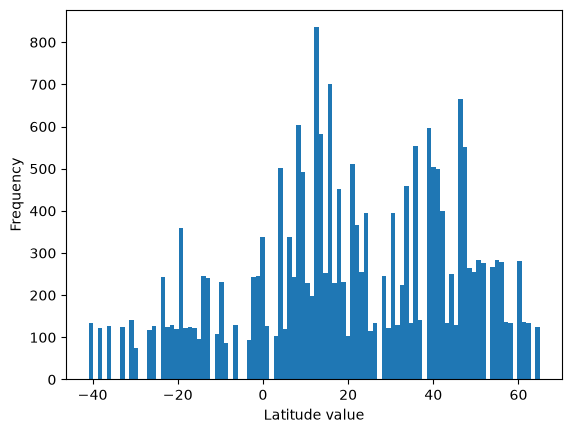

In [21]:
data['latitude'].plot(kind='hist', bins=100)
plt.xlabel('Latitude value')

Text(0, 0.5, 'Food produced (tonnes)')

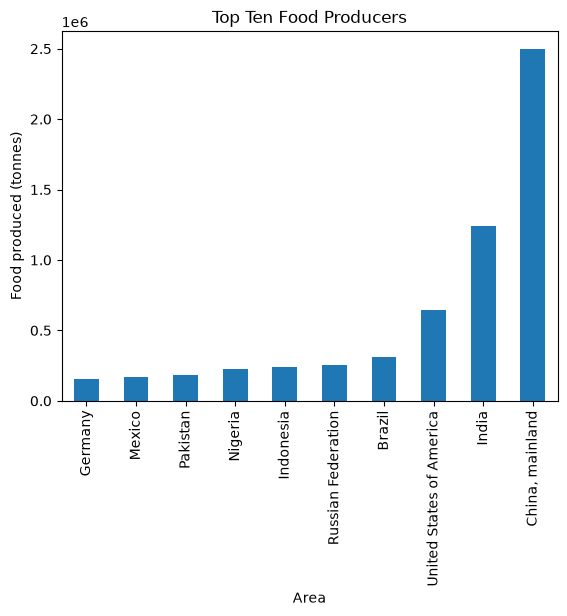

In [22]:
plot_data = data[data['Element'] == 'Food']
plot_data = plot_data.groupby('Area')['Y2013'].sum()
plot_data.sort_values()[-10:].plot(kind='bar')
plt.title("Top Ten Food Producers")
plt.ylabel("Food produced (tonnes)")

---
## Part B: real life: who depends on a single staple, and has that changed?

**Question:** food security is about concentration risk. A country that gets most of its staple food from one crop is exposed if that crop fails or its price spikes. **Which countries lean hardest on one staple, and has the world diversified since 1961?** And a second question: **how much of the world's cereal goes to animals rather than people?**

**Data:** FAOSTAT food balance sheets: for each country, item and year, how much was supplied as *Food* or *Feed*, in thousands of tonnes.

**Before any analysis the data needs cleaning**, and the cleaning is most of the lesson: real data is messy.

### 1. Cleaning
**Check 1: duplicates.** The same country + item + element should appear once.

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

raw = pd.read_csv('FAO.csv', encoding='ISO-8859-1')
year_cols = [c for c in raw.columns if c.startswith('Y') and c[1:].isdigit()]
print(f'{raw.shape[0]:,} rows | units: {raw["Unit"].unique().tolist()} | elements: {raw["Element"].unique().tolist()}')

key = ['Area', 'Item', 'Element']
dupes = raw[raw.duplicated(key, keep=False)]
print(f'{raw.duplicated(key).sum()} duplicate rows, all from these items: {dupes["Item"].unique().tolist()}')
print('copies identical in every year column:',
      bool((dupes.groupby(key)[year_cols].nunique(dropna=False) == 1).all().all()))

naive_china = raw[(raw['Element'] == 'Food') & (raw['Area'] == 'China, mainland')]['Y2013'].sum()   # what Part A's chart would use
raw = raw.drop_duplicates(key)

21,477 rows | units: ['1000 tonnes'] | elements: ['Food', 'Feed']
459 duplicate rows, all from these items: ['Eggs', 'Milk - Excluding Butter']
copies identical in every year column: True


**Check 2: aggregates.** The item list contains group totals ('Cereals - Excluding Beer') *and* their parts (Wheat, Rice…). If the group row is just the sum of its parts, adding both double-counts. Test it on the world total for 2013:

In [24]:
food13 = raw[raw['Element'] == 'Food'].groupby('Item')['Y2013'].sum()
parts = {
    'Cereals - Excluding Beer': ['Wheat and products', 'Rice (Milled Equivalent)', 'Barley and products', 'Maize and products',
                                 'Rye and products', 'Oats', 'Millet and products', 'Sorghum and products', 'Cereals, Other'],
    'Starchy Roots': ['Cassava and products', 'Potatoes and products', 'Sweet potatoes', 'Yams', 'Roots, Other'],
    'Meat': ['Bovine Meat', 'Mutton & Goat Meat', 'Pigmeat', 'Poultry Meat', 'Meat, Other'],
    'Vegetables': ['Tomatoes and products', 'Onions', 'Vegetables, Other'],
}
check = pd.DataFrame({group: {'group row (1000 t)': food13[group], 'sum of its parts (1000 t)': food13[members].sum()}
                      for group, members in parts.items()}).T
check['ratio'] = check['group row (1000 t)'] / check['sum of its parts (1000 t)']
check.round(2)

,group row (1000 t),sum of its parts (1000 t),ratio
Cereals - Excluding Beer,1029017,1029010,1.0
Starchy Roots,443357,443349,1.0
Meat,302411,302399,1.0
Vegetables,982974,982964,1.0


Ratios of 1.00: the group rows are pure double-counts. I checked 16 group items this way (the same holds for Fruits, Pulses, Oilcrops and the rest); three more (Sugar Crops, Aquatic Products Other, Miscellaneous) equal the sum of their parts exactly. All 19 are dropped below.

In [25]:
AGGREGATES = ['Cereals - Excluding Beer', 'Starchy Roots', 'Vegetables', 'Fruits - Excluding Wine', 'Meat', 'Pulses',
              'Sugar & Sweeteners', 'Vegetable Oils', 'Oilcrops', 'Alcoholic Beverages', 'Stimulants', 'Spices',
              'Animal fats', 'Fish, Seafood', 'Offals', 'Treenuts', 'Sugar Crops', 'Aquatic Products, Other', 'Miscellaneous']
leaf = raw[~raw['Item'].isin(AGGREGATES)]
print(f'{len(raw):,} -> {len(leaf):,} rows; {leaf["Item"].nunique()} individual items left')

clean_china = leaf[(leaf['Element'] == 'Food') & (leaf['Area'] == 'China, mainland')]['Y2013'].sum()
print(f"China's 2013 food supply: {naive_china:,.0f} (summing everything, as in Part A) vs {clean_china:,.0f} (cleaned) thousand tonnes")

21,018 -> 16,735 rows; 96 individual items left
China's 2013 food supply: 2,499,252 (summing everything, as in Part A) vs 1,249,625 (cleaned) thousand tonnes


**Reshape.** One row per country × item × element × year is far easier to group and plot than 53 year columns. `melt` does it in one line.

In [26]:
long = leaf.melt(id_vars=['Area', 'Item', 'Element'], value_vars=year_cols, var_name='Year', value_name='kt')
long['Year'] = long['Year'].str[1:].astype(int)

print('negative supply values:')
display(long[long['kt'] < 0])                      # a supply cannot be negative: treat as missing
long.loc[long['kt'] < 0, 'kt'] = np.nan

print(f'{len(long):,} rows, {long["kt"].isna().mean() * 100:.0f}% missing')
long.head()

negative supply values:


,Area,Item,Element,Year,kt
861349,Japan,Oats,Food,2012,-169.0
878084,Japan,Oats,Food,2013,-246.0


886,955 rows, 10% missing


,Area,Item,Element,Year,kt
0,Afghanistan,Wheat and products,Food,1961,1928.0
1,Afghanistan,Rice (Milled Equivalent),Food,1961,183.0
2,Afghanistan,Barley and products,Feed,1961,76.0
3,Afghanistan,Barley and products,Food,1961,237.0
4,Afghanistan,Maize and products,Feed,1961,210.0


**Check 3: who is in the data in every year?** Countries come and go (new states, splits). If a country only appears from 1992, any world total jumps in 1992 for a reason that has nothing to do with food.

In [27]:
food_total = long[long['Element'] == 'Food'].groupby(['Area', 'Year'])['kt'].sum(min_count=1).unstack()
years_of_data = food_total.notna().sum(axis=1).sort_values()
complete = years_of_data[years_of_data == 53].index          # countries with data in every year 1961-2013
print(f'{len(complete)} of {len(years_of_data)} countries have data in all 53 years')
display(years_of_data.head(8).to_frame('years of data (of 53)').T)

change = pd.DataFrame({'all countries': food_total.sum().pct_change(),
                       'complete countries only': food_total.loc[complete].sum().pct_change()}) * 100
print('% change in world food supply vs the previous year:')
display(change.loc[[1991, 1992, 1993]].round(1))

146 of 174 countries have data in all 53 years


Area,Sudan,Serbia,Montenegro,Luxembourg,Belgium,Ethiopia,Czechia,Slovakia
years of data (of 53),2,8,8,14,14,21,21,21


% change in world food supply vs the previous year:


,all countries,complete countries only
Year,,
1991,1.8,1.8
1992,11.3,3.4
1993,3.3,2.7


**What the cleaning found, and why it matters:**
- **459 duplicate rows**: Eggs and Milk each appear under two item codes with identical values. Removed.
- **19 aggregate items double-count their parts.** Part A's approach gives China's 2013 food supply as 2,499,252 thousand tonnes; cleaned, it is 1,249,625: exactly double.
- **Two impossible values**: Japan's Oats are negative in 2012 and 2013. Treated as missing.
- **Countries that only appear mid-series.** 28 of 174 countries lack some years (mostly new states such as the ex-Soviet republics, plus Serbia, Montenegro, Sudan, Ethiopia, Belgium and Luxembourg). Adding them in the year they appear makes the world total jump **11.3% in 1992**, against 3.4% for the 146 countries with complete data. So every trend below uses only those **146 countries**.

### 2. Question 1: who leans hardest on one staple?
**Staples** here are cereals, roots/tubers and plantains. For each country and year: the share of its staple tonnage that comes from its single biggest staple. (Why not *all* foods? By weight, milk and vegetables dominate and say little about security: milk is the biggest single item in about half the countries.)

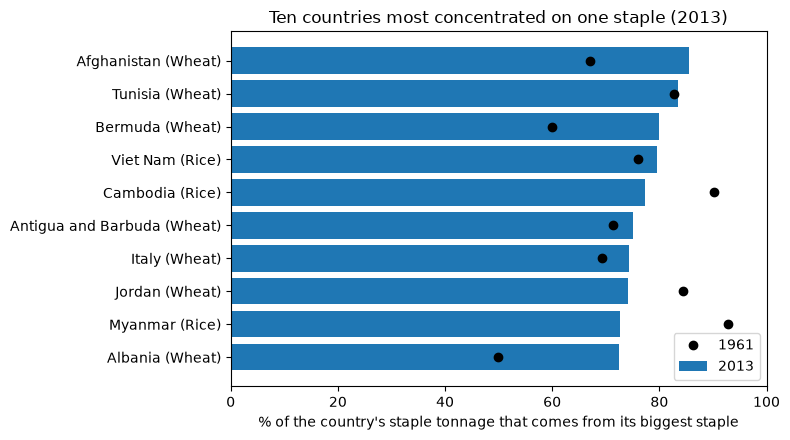

,staple_2013,share_2013,share_1961
Area,,,
Afghanistan,Wheat and products,0.86,0.67
Tunisia,Wheat and products,0.83,0.83
Bermuda,Wheat and products,0.80,0.60
Viet Nam,Rice (Milled Equivalent),0.80,0.76
Cambodia,Rice (Milled Equivalent),0.77,0.90
Antigua and Barbuda,Wheat and products,0.75,0.71
Italy,Wheat and products,0.74,0.69
Jordan,Wheat and products,0.74,0.84
Myanmar,Rice (Milled Equivalent),0.73,0.93


In [28]:
STAPLES = ['Wheat and products', 'Rice (Milled Equivalent)', 'Maize and products', 'Barley and products', 'Rye and products',
           'Oats', 'Millet and products', 'Sorghum and products', 'Cereals, Other', 'Cassava and products',
           'Potatoes and products', 'Sweet potatoes', 'Yams', 'Roots, Other', 'Plantains']

def top_staple(year):
    g = long[(long['Element'] == 'Food') & long['Item'].isin(STAPLES) & long['Area'].isin(complete)
             & (long['Year'] == year) & (long['kt'] > 0)]
    top = g.loc[g.groupby('Area')['kt'].idxmax()].set_index('Area')          # each country's biggest staple
    return pd.DataFrame({'staple': top['Item'], 'share': top['kt'] / g.groupby('Area')['kt'].sum()})

dep = top_staple(1961).join(top_staple(2013), lsuffix='_1961', rsuffix='_2013')
dep['change'] = dep['share_2013'] - dep['share_1961']

top10 = dep.sort_values('share_2013', ascending=False).head(10).iloc[::-1]
labels = top10.index + ' (' + top10['staple_2013'].str.replace(r' and products| \(Milled Equivalent\)', '', regex=True) + ')'
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(labels, top10['share_2013'] * 100, color='tab:blue', label='2013')
ax.plot(top10['share_1961'] * 100, labels, 'ko', label='1961')
ax.set_xlabel('% of the country\'s staple tonnage that comes from its biggest staple'); ax.set_xlim(0, 100)
ax.set_title('Ten countries most concentrated on one staple (2013)'); ax.legend()
plt.tight_layout(); plt.show()

top10[['staple_2013', 'share_2013', 'share_1961']].iloc[::-1].round(2)

In [29]:
print(f'median country: {dep["share_1961"].median() * 100:.0f}% of staples from the biggest one in 1961 -> {dep["share_2013"].median() * 100:.0f}% in 2013')
print(f'{(dep["change"] < 0).mean() * 100:.0f}% of countries became less concentrated; '
      f'{(dep["staple_1961"] != dep["staple_2013"]).sum()} of {len(dep)} changed which staple is their biggest')

print('\nhow many countries have each staple as their biggest:')
display(pd.DataFrame({'1961': dep['staple_1961'].value_counts(), '2013': dep['staple_2013'].value_counts()})
        .fillna(0).astype(int).sort_values('2013', ascending=False).head(6))

cols = ['staple_1961', 'share_1961', 'staple_2013', 'share_2013', 'change']
print('most diversified:');  display(dep.sort_values('change').head(5)[cols].round(2))
print('most concentrated:'); display(dep.sort_values('change', ascending=False).head(5)[cols].round(2))

median country: 53% of staples from the biggest one in 1961 -> 49% in 2013
68% of countries became less concentrated; 47 of 146 changed which staple is their biggest

how many countries have each staple as their biggest:


,1961,2013
Wheat and products,52,69
Rice (Milled Equivalent),24,30
Maize and products,14,14
Cassava and products,16,13
Potatoes and products,14,6
"Roots, Other",6,5


most diversified:


,staple_1961,share_1961,staple_2013,share_2013,change
Area,,,,,
United Republic of Tanzania,Cassava and products,0.67,Cassava and products,0.28,-0.39
Malawi,Maize and products,0.71,Potatoes and products,0.35,-0.37
Central African Republic,Cassava and products,0.78,Cassava and products,0.43,-0.35
Cabo Verde,Maize and products,0.58,Rice (Milled Equivalent),0.26,-0.32
Vanuatu,"Roots, Other",0.88,"Roots, Other",0.58,-0.30


most concentrated:


,staple_1961,share_1961,staple_2013,share_2013,change
Area,,,,,
Djibouti,Wheat and products,0.33,Wheat and products,0.65,0.31
New Caledonia,Wheat and products,0.27,Wheat and products,0.52,0.25
Albania,Wheat and products,0.50,Wheat and products,0.72,0.23
Saudi Arabia,Wheat and products,0.28,Wheat and products,0.49,0.21
Bermuda,Wheat and products,0.60,Wheat and products,0.80,0.20


- **The most concentrated countries are single-grain countries (2013):** Afghanistan (86% of staple tonnage from wheat), Tunisia (83% wheat), Bermuda (80% wheat), Viet Nam (80% rice), Cambodia (77% rice).
- **The world diversified a little.** The typical country got 53% of its staples from its biggest one in 1961 and 49% in 2013; 68% of countries became less concentrated, and 47 of 146 changed which staple is their biggest.
- **Wheat is winning.** It is the biggest staple in 69 countries, up from 52 in 1961 (rice 24 to 30; potatoes fell from 14 to 6, cassava from 16 to 13).
- **Big movers:** Tanzania diversified away from cassava (67% to 28%) and Malawi went from maize (71%) to potatoes (35%); Djibouti (33% to 65%) and Saudi Arabia (28% to 49%) became far more wheat-dependent.
- **Concentration is not the same as vulnerability.** Italy is on the list (74% wheat), yet it has a varied diet and its own farms. This measure sees tonnes of staples only; it can't tell home-grown from imported, which is what would show real exposure.

### 3. Question 2: how much cereal goes to animals?
The `Feed` element lets us split each country's cereal use into food for people and feed for animals. Share of cereal use that is feed: for the whole world, and for the *typical* (median) country.

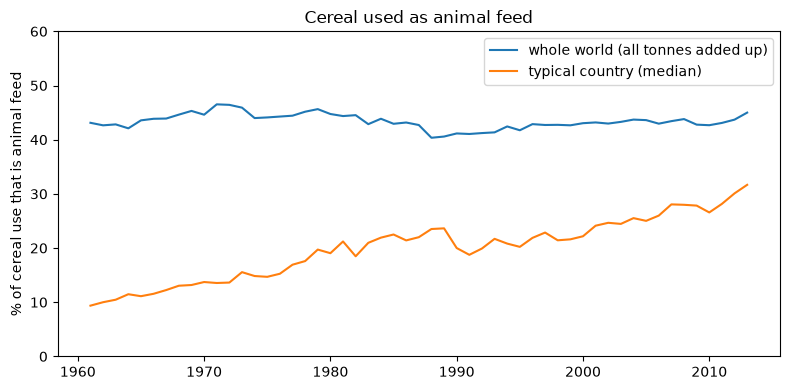

whole world: 43% (1961) -> 45% (2013)
typical country: 9% (1961) -> 32% (2013)
cereal food use grew 2.9x, feed use 3.1x


In [30]:
CEREALS = ['Wheat and products', 'Rice (Milled Equivalent)', 'Maize and products', 'Barley and products',
           'Rye and products', 'Oats', 'Millet and products', 'Sorghum and products', 'Cereals, Other']
cer = long[long['Item'].isin(CEREALS) & long['Area'].isin(complete)]

by_country = cer.groupby(['Area', 'Year', 'Element'])['kt'].sum().unstack('Element')
by_country['feed_share'] = by_country['Feed'] / (by_country['Feed'] + by_country['Food'])
typical = by_country['feed_share'].groupby('Year').median()

world = cer.groupby(['Year', 'Element'])['kt'].sum().unstack()
world_share = world['Feed'] / (world['Feed'] + world['Food'])

plt.figure(figsize=(8, 4))
plt.plot(world_share.index, world_share * 100, label='whole world (all tonnes added up)')
plt.plot(typical.index, typical * 100, label='typical country (median)')
plt.ylim(0, 60); plt.ylabel('% of cereal use that is animal feed'); plt.title('Cereal used as animal feed')
plt.legend(); plt.tight_layout(); plt.show()

print(f'whole world: {world_share[1961] * 100:.0f}% (1961) -> {world_share[2013] * 100:.0f}% (2013)')
print(f'typical country: {typical[1961] * 100:.0f}% (1961) -> {typical[2013] * 100:.0f}% (2013)')
print(f'cereal food use grew {world.loc[2013, "Food"] / world.loc[1961, "Food"]:.1f}x, feed use {world.loc[2013, "Feed"] / world.loc[1961, "Feed"]:.1f}x')

- **World-wide, the animal-feed share of cereal use is flat**: 43% in 1961, 45% in 2013 (cereal food use grew 2.9x, feed use 3.1x).
- **But the typical country changed completely**: 9% in 1961, 32% in 2013. A tenth of cereal use going to animals became a third.
- **Why the two disagree:** the world number is dominated by a handful of huge countries. That is probably the reason, but I haven't tested it. Either way, the median is the better picture of what happened in most countries.

### Finding
**The world has only slightly diversified its staples, and wheat keeps winning.** The typical country now gets 49% of its staple tonnage from one crop (53% in 1961); 68% of countries are less concentrated than in 1961, yet wheat became the biggest staple in 69 countries (52 in 1961), and the most concentrated countries live on a single grain (wheat in Afghanistan and Tunisia, rice in Viet Nam and Cambodia). Separately, the typical country now feeds about a third of its cereals to animals, up from 9%, even though the worldwide share is flat at about 45%.

**Caveats:** tonnes are not calories or nutrition; I chose the list of 15 staples myself; concentration is not vulnerability (the data doesn't split imports from home production); only the 146 countries with data in all 53 years are used; the data ends in 2013.

**Next:** add imports and production to see who is truly exposed, and weight by calories instead of tonnes.